# Explainable AI: Variable Importance, SHAP, and LIME — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 7**

This notebook follows the R lecture `lectures/week7/explainableAI.Rmd`: XGBoost for diabetes in NHANES, then permutation importance, SHAP, and LIME.

| R | Python |
|---|---|
| `predict(xgb_fit, X, predcontrib = TRUE)` | `xgb_fit.predict(dmat, pred_contribs=True)` or `shap.TreeExplainer` |
| `shapviz::sv_importance(kind = "beeswarm")` | `shap.plots.beeswarm` |
| `shapviz::sv_dependence` | `shap.plots.scatter` |
| `shapviz::sv_waterfall` | `shap.plots.waterfall` |
| `lime::lime` / `explain` | `lime.lime_tabular.LimeTabularExplainer` |

Install with `pip install xgboost shap lime`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

## The data: NHANES adults, ordinal factors coded as numbers

In [2]:
nh = pd.read_csv(DATA + "nhanes_adults.csv")
edu = ["8th Grade", "9 - 11th Grade", "High School", "Some College", "College Grad"]
hg = ["Excellent", "Vgood", "Good", "Fair", "Poor"]
d = nh.drop(columns=["Race1"]).assign(
    Education=lambda x: x.Education.map({k: i + 1 for i, k in enumerate(edu)}),
    HealthGen=lambda x: x.HealthGen.map({k: i + 1 for i, k in enumerate(hg)}),
    Male=lambda x: (x.Gender == "male").astype(int),
    PhysActive=lambda x: (x.PhysActive == "Yes").astype(int),
    Smoke100=lambda x: (x.Smoke100 == "Yes").astype(int)).drop(columns="Gender")
X = d.drop(columns="Diabetes"); y = (d.Diabetes == "Yes").astype(int)
print(X.shape, round(y.mean(), 3))

(3570, 16) 0.117


## XGBoost with early stopping

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)
dtrain = xgb.DMatrix(X_train, label=y_train)
params = {"objective": "binary:logistic", "eval_metric": "auc", "eta": 0.05,
          "max_depth": 3, "subsample": 0.8, "colsample_bytree": 0.8}
cv = xgb.cv(params, dtrain, num_boost_round=1000, nfold=5, early_stopping_rounds=30, seed=1)
best_n = int(cv["test-auc-mean"].idxmax()) + 1
xgb_fit = xgb.train(params, dtrain, num_boost_round=best_n)
p_test = xgb_fit.predict(xgb.DMatrix(X_test))
print("rounds:", best_n, " test AUC:", round(roc_auc_score(y_test, p_test), 3))

rounds: 92  test AUC: 0.832


## Global: built-in gain importance and permutation importance

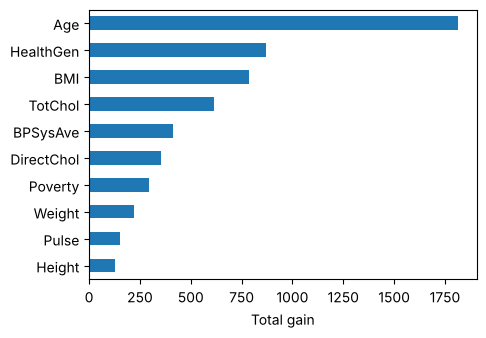

In [4]:
gain = pd.Series(xgb_fit.get_score(importance_type="total_gain")).sort_values()
gain.tail(10).plot.barh(figsize=(5, 3.5)); plt.xlabel("Total gain"); plt.show()

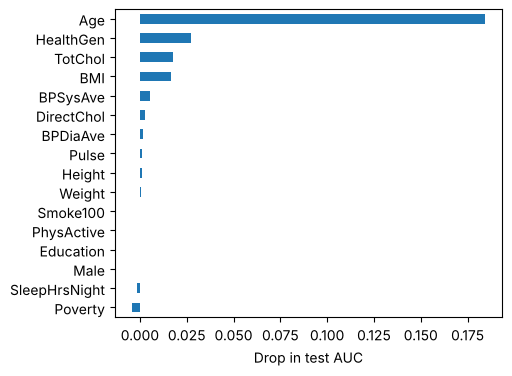

In [5]:
rng = np.random.default_rng(1)
auc0 = roc_auc_score(y_test, p_test)
perm = {}
for j in X_test.columns:
    drops = []
    for _ in range(10):
        Xp = X_test.copy(); Xp[j] = rng.permutation(Xp[j].to_numpy())
        drops.append(auc0 - roc_auc_score(y_test, xgb_fit.predict(xgb.DMatrix(Xp))))
    perm[j] = np.mean(drops)
pd.Series(perm).sort_values().plot.barh(figsize=(5, 4)); plt.xlabel("Drop in test AUC"); plt.show()

## SHAP
TreeSHAP is built into XGBoost (`pred_contribs=True`); the last column is the baseline $\phi_0$. Values are on the log-odds scale and add up to the prediction.

In [6]:
contrib = xgb_fit.predict(xgb.DMatrix(X_test), pred_contribs=True)
phi0, S = contrib[0, -1], contrib[:, :-1]
logit = np.log(p_test / (1 - p_test))
print("additivity holds:", np.allclose(phi0 + S.sum(1), logit, atol=1e-4))

additivity holds: True


The `shap` package gives the standard plots:

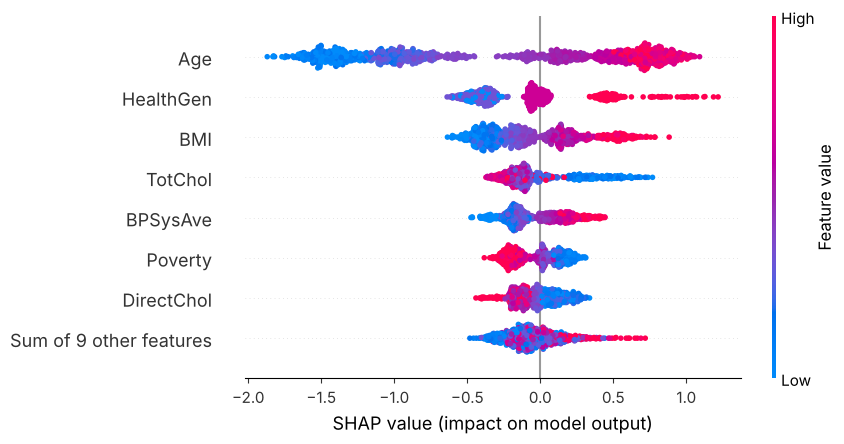

In [7]:
explainer = shap.TreeExplainer(xgb_fit)
sv = explainer(X_test)
shap.plots.beeswarm(sv, max_display=8)

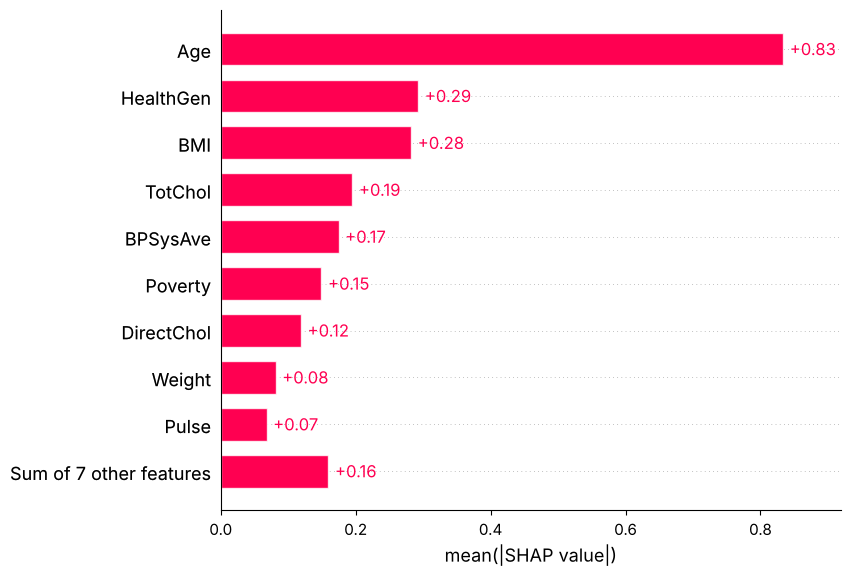

In [8]:
shap.plots.bar(sv, max_display=10)

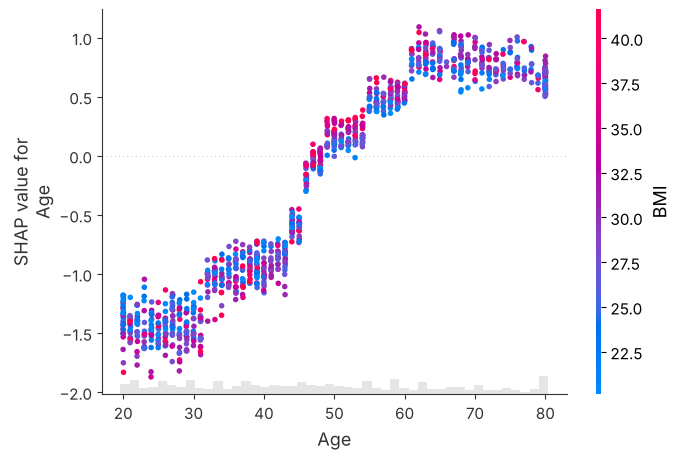

In [9]:
shap.plots.scatter(sv[:, "Age"], color=sv[:, "BMI"])

One person: the highest-risk test patient.

predicted probability: 0.75  diabetes: 1


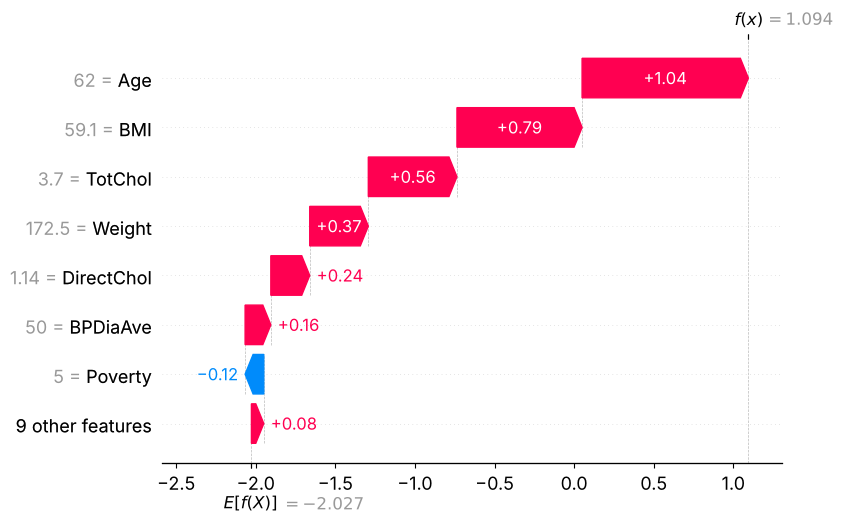

In [10]:
i = int(np.argmax(p_test))
print("predicted probability:", round(float(p_test[i]), 2), " diabetes:", int(y_test.iloc[i]))
shap.plots.waterfall(sv[i], max_display=8)

## LIME
Perturb one patient, predict the neighbors, and fit a weighted sparse linear model. Rerun with a different seed to see how stable the explanation is.

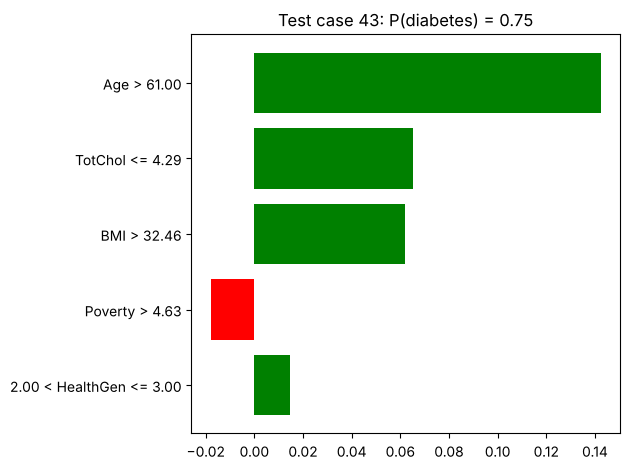

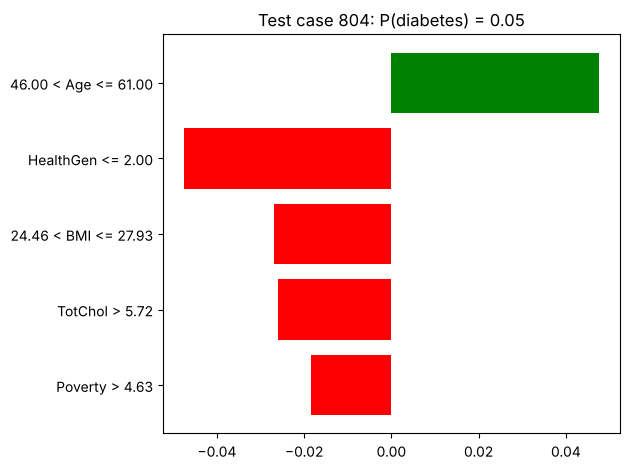

In [11]:
from lime.lime_tabular import LimeTabularExplainer

def predict_proba(a):
    p = xgb_fit.predict(xgb.DMatrix(pd.DataFrame(a, columns=X_train.columns)))
    return np.c_[1 - p, p]

lime_exp = LimeTabularExplainer(X_train.to_numpy(), feature_names=list(X_train.columns),
                                class_names=["No", "Yes"], mode="classification", random_state=1)
for case in (i, int(np.argmin(np.abs(p_test - 0.05)))):
    e = lime_exp.explain_instance(X_test.iloc[case].to_numpy(), predict_proba, num_features=5, labels=(1,))
    e.as_pyplot_figure(label=1); plt.title(f"Test case {case}: P(diabetes) = {p_test[case]:.2f}")
    plt.tight_layout(); plt.show()